L=10.0 [mm], d=1.0 [mm], order=3, phi0=1.0, lambda_target=2.0
sum(fes.FreeDofs()) = 126756
Iteration=11
Average energy density =  -54.9801
'Macroscopic' vertical stretch:  2.011075241956698
uniaxial_sigma_11=-0.205820249675
Average compressive stress =  -0.20824


WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

 
Iteration=12
Average energy density =  -54.98015
'Macroscopic' vertical stretch:  2.010850370315568
uniaxial_sigma_11=-0.205820249675
Average compressive stress =  -0.20793


WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

 
Iteration=13
Average energy density =  -54.9801
'Macroscopic' vertical stretch:  2.0103124246688635
uniaxial_sigma_11=-0.205820249675
Average compressive stress =  -0.20685


WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

... (10 outputs left out)

 
Iteration=19
Average energy density =  nan
'Macroscopic' vertical stretch:  2.021373592859533
uniaxial_sigma_11=-0.205820249675
Average compressive stress =  nan


WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

 
Iteration=20
Average energy density =  nan
'Macroscopic' vertical stretch:  nan
uniaxial_sigma_11=-0.205820249675
Average compressive stress =  nan


WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

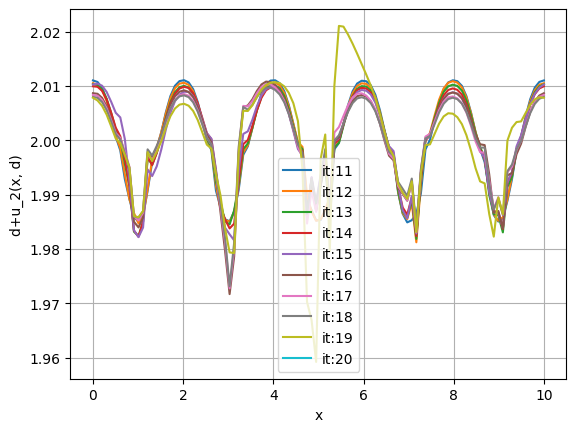

In [23]:
from ngsolve import *
from ngsolve.webgui import Draw
from ClassGels3 import gel2d
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# READ PARAMETERS
# It will be assumed that the arguments passed from shell
# are, in that order:
# the length; the thickness; the order for the finite element space;
# the initial polymer volume fraction phi0; 
# the target theoretical uniaxial stretch lambda_h 
# For example,
#    100 20 3 0.9 2.0
# means L=100, d=20, order=3, phi0=0.9, lambda_h=2.0
# ---------------------------------------------------------
# data = sys.argv
day = '20261122'
phi0,lamb,time = [1.0,2.0,'1403']  # n_waves=5, amp_rel=2%, maxh_coarse=d*(4e-2), maxh_fine=d*(4e-2), tol=1e-3; maxits=100;
# phi0,lamb,time = [1.0,2.0,'1401']  # n_waves=5, amp_rel=3%, maxh_coarse=d*(4e-2), maxh_fine=d*(4e-2), tol=1e-3; maxits=100;
# phi0,lamb,time = [1.0,2.0,'1359']  # n_waves=5, amp_rel=10%, maxh_coarse=d*(4e-2), maxh_fine=d*(4e-2), tol=1e-3; maxits=100;
# phi0,lamb,time = [1.0,2.0,'1321']  # n_waves=5, amp_rel=1%, maxh_coarse=d*(4e-2), maxh_fine=d*(4e-2), tol=1e-3; maxits=100;
# phi0,lamb,time = [1.0,2.0,'1306']  # n_waves=5, amp_rel=1%, maxh_coarse=d*(4e-2), maxh_fine=d*(4e-2), tol=1e-2; maxits=20;
# lamb,time = [2.0,'1247']  # n_waves=5, amp_rel=1%
# lamb,time = [2.0,'1237']  # n_waves=5, amp_rel=100%
# lamb,time = [6.0,'0851']  # n_waves=5, amp_rel=100%
# lamb,time = [6.0,'0849']  # n_waves=10, amp_rel=100%
# lamb,time = [6.0,'0845']  # n_waves=10, amp_rel=200%, nan before 10 iterations
# lamb,time = [8.0,'0840']  # n_waves=10, amp_rel=200%
# lamb,time = [8.0,'0835']  # n_waves=5, amp_rel = 200%
data = ['dummy', '10', '1', '3', str(phi0), str(lamb)]
# data = ['dummy', '10', '1', '3', '0.9', str(lamb)]
# data = ['dummy', '10', '1', '3', '0.9', '2.1']
# data = ['dummy', '10', '1', '3', '0.9', '2.0']
# data = ['dummy', '100', '20', '3', '0.9', '2.0']
L = float(data[1])
d = float(data[2])
order = int(data[3])
phi0 = float(data[4])
# mu_input = float(data[5])    
# mu_bar = -mu_input  # internal sign convention
# print(f'L={L} [mm], d={d} [mm], order={order}, phi0={phi0}, mu_bar={mu_bar}')
lambda_target = float(data[5])
print(f'L={L} [mm], d={d} [mm], order={order}, phi0={phi0}, lambda_target={lambda_target}')
# gel = gel2d(L,d,phi0,mu_bar)
gel = gel2d(L,d,phi0,lambda_target)
# ---------------------------------------------------------
# LOAD MESH
# ---------------------------------------------------------
# mesh_file = 'meshes/mesh.vol'
mesh_file = 'meshes/meshPeriodic.vol'
mesh = Mesh(mesh_file)
# ---------------------------------------------------------
# FINITE ELEMENT SPACE
# Finite element space with zero-displacement boundary condition on the whole interface
# and periodic boundary conditions identifying left and right.
# ---------------------------------------------------------
fes = Periodic(VectorH1(mesh, order=order, \
                    dirichlet="bot"))
print(f'sum(fes.FreeDofs()) = {sum(fes.FreeDofs())}')
# ---------------------------------------------------------
# LOAD SIMULATION
# ---------------------------------------------------------
simulation_name = 'test' + day + time
gfu = GridFunction(fes) 
# maxits = 100
# indexes_iterations = [0]
# indexes_iterat3%ions = [50, 100,150, 200]
# indexes_iterations = [200]
# indexes_iterations = range(0,1+1)
# indexes_iterations = range(0,3+1)
# indexes_iterations = range(0,5+1)
# indexes_iterations = range(0,10+1)
indexes_iterations = range(11,20+1)
# indexes_iterations = range(21,30+1)
# indexes_iterations = range(31,40+1)
# indexes_iterations = range(41,50+1)
# indexes_iterations = range(61,63+1)
# indexes_iterations = range(91,100+1)
# indexes_iterations = range(100,103+1)
# indexes_iterations = range(160,165+1)
# indexes_iterations = range(190,192+1)
# indexes_iterations = range(190,194+1)
# indexes_iterations = range(310,321+1)
for it in indexes_iterations:
    filename_main = gel.filename_main(simulation_name)
    filename = filename_main + '_Newton=' + str(it).zfill(2)
    #
    gfu.Load(filename + '.gfu')
    F = Id(2) + Grad(gfu)
    # Draw(gel.W(F), mesh, deformation=u)
    # Draw(gel.W(F), mesh)
    print(f'Iteration={it}')
    print('Average energy density = ', round(Integrate(gel.W(F), mesh)/(L*d),5))   
    vertex_values = [(y+gfu[1])(mesh(*p)) for p in mesh.ngmesh.Points()]
    print(f'\'Macroscopic\' vertical stretch: ', max(vertex_values)/gel.d) 
    uniaxial_compressive_stress = -gel.entropic_unit*gel.gamma*(lambda_target-1/lambda_target) 
    print(f'uniaxial_sigma_{11}={uniaxial_compressive_stress}')
    # gel.mu_bar.Set(previous_mu_bar)
    print('Average compressive stress = ', round(Integrate(gel.sigma_xx(F), mesh)/(L*d),5))  
    #
    X = np.linspace(0.0, L, 100)
    eps = 1e-9
    Y = np.full_like(X, d-eps)
    # Evaluate gfu[1] along (x, d)
    vals = Y+np.asarray(gfu[1](mesh(X, Y))).ravel()
    plt.plot(X, vals, label=f'it:{it}')
    plt.xlabel("x")
    plt.ylabel("d+u_2(x, d)")
    # plt.ylim([1.995, 2.005])
    plt.grid(True)
    plt.legend()
    # plt.show()
    #
    Draw(-gel.sigma_xx(F), mesh, deformation=gfu, min=0.1, max =3,settings={"Objects": {"Wireframe": False}})
    # Draw(y+gfu[1], mesh, deformation=gfu)
    print(' ')

In [ ]:
from ngsolve import *
from ngsolve.webgui import Draw
mesh_file = 'meshes/meshPeriodic.vol'
mesh = Mesh(mesh_file)
print(f'nElements = {mesh.ne}, nVertices = {mesh.nv}')
Draw(x,mesh)


In [7]:
from ngsolve import *
from ngsolve.webgui import Draw
from ClassGels3 import *
import scipy.optimize

gel=gel2d(length=10.0,thickness=1.0,phi0=1.0,lambda_target=2.0)

mu_value = -0.04
def auxFunctionLambdaMu(lamb):
    return gel.mu_fun(lamb) - mu_value
# Among 100 trials, chooses the value of lambda
# for which mu_fun is closest to the target mu_value
lambda_start = 1.0001; lambda_end = 10; numPoints=1000;
lambda_values = np.linspace(lambda_start, lambda_end, numPoints)        
lambda_initial_fsolve = lambda_start
best_abs_dist= abs(auxFunctionLambdaMu(lambda_start))
for lamb in lambda_values:
    dist = auxFunctionLambdaMu(lamb)
    if abs(dist) < best_abs_dist:
        best_abs_dist = abs(dist)
        lambda_initial_fsolve = lamb   
# and finally, for higher precision, fsolve is called
# This seems to be necessary since the function mu_fun is potentially 
# extremely sensitive to changes in lambda
lamb = (scipy.optimize.fsolve(auxFunctionLambdaMu, lambda_initial_fsolve))[0]   # approximate solution to  self.mu_fun(lamb) = mu_value, for given mu_value          

print(lamb)
print(gel.mu_bar.Get())

2.589321883893683
-0.09162385923948445
